Developing a grammar scoring engine for spoken data samples, using deep learning.

The ground truth labels are MOS Likert Grammar Scores for each audio instance.

Task is to build a model that can take an audio input, and generate grammar score as continuous variable between 1 to 5. 

# The Approach

### 1. Manual Cascaded feature engineering pipeline with native ML model

### 2. Combining sentence embeddings with MFCC, and audio prasody features

In [5]:
# Loading the dataset


import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings

warnings.filterwarnings('ignore')

In [6]:
folder_path = '/Users/aryansharma/Desktop/Dataset_Final'

train_labels = pd.read_csv(folder_path + '/train.csv')
test_labels = pd.read_csv(folder_path + '/test.csv')

In [7]:
train_labels

,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0
...,...,...
764,audio_390.wav,5.0
765,audio_766.wav,4.5
766,audio_571.wav,2.0
767,audio_393.wav,4.5


In [8]:
# loading train audio files: from folder_path / train


train_labels_path = os.path.join(folder_path, 'train.csv')
audio_dir_train = os.path.join(folder_path, 'train')


In [9]:
# loading the test files 

test_labels_path = os.path.join(folder_path, 'test.csv')
audio_dir_test = os.path.join(folder_path, 'test')


In [10]:
missing_files = []
valid_indices = []
for idx, row in train_labels.iterrows():
    fname = row['filename']
    fpath = os.path.join(audio_dir_train, fname)
    if os.path.exists(fpath):
        valid_indices.append(idx)
    else:
        missing_files.append(fname)

In [11]:
print(f"Verified: {len(valid_indices)}/{len(train_labels)} audio files found in {audio_dir_train}.")

Verified: 769/769 audio files found in /Users/aryansharma/Desktop/Dataset_Final/train.


In [12]:

audio_data_train = []
if os.path.exists(audio_dir_train):
    for file in os.listdir(audio_dir_train):
        if file.endswith('.wav'):
            audio_full_path = os.path.join(audio_dir_train, file)
            
            try:
                audio_id = int(file.replace('audio_', '').replace('.wav', ''))
            except ValueError:
                audio_id = -1
                
            audio_data_train.append({
                'audio_id': audio_id,
                'filename': file,
                'file_path': audio_full_path
            })

# 3. Convert to DataFrame with explicit column names
df_files = pd.DataFrame(audio_data_train, columns=['audio_id', 'filename', 'file_path'])

In [13]:
#audio_data

In [14]:


# 2. Sort numerically by audio_id
df_files = df_files.sort_values(by='audio_id').reset_index(drop=True)

# 3. Merge with train_labels (on 'filename')
train_audio_data = pd.merge(df_files, train_labels[['filename', 'label']], on='filename', how='inner')


train_audio_data = train_audio_data[['audio_id', 'filename', 'file_path', 'label']]

In [15]:
train_audio_data.head(5)

,audio_id,filename,file_path,label
0,0,audio_0.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,3.0
1,1,audio_1.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,3.5
2,2,audio_2.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,2.5
3,3,audio_3.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,3.0
4,4,audio_4.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,2.5


In [16]:
# similarly loading the test file with the test data set.



audio_data_test = []
if os.path.exists(audio_dir_test):
    for file in os.listdir(audio_dir_test):
        if file.endswith('.wav'):
            audio_full_path = os.path.join(audio_dir_test, file)
            
            try:
                audio_id = int(file.replace('audio_', '').replace('.wav', ''))
            except ValueError:
                audio_id = -1
                
            audio_data_test.append({
                'audio_id': audio_id,
                'filename': file,
                'file_path': audio_full_path
            })

# 3. Convert to DataFrame with explicit column names
df_files = pd.DataFrame(audio_data_test, columns=['audio_id', 'filename', 'file_path'])

In [17]:
df_files = df_files.sort_values(by='audio_id').reset_index(drop=True)

test_audio_data = pd.merge(df_files, test_labels[['filename', 'label']], on='filename', how='inner')


test_audio_data = test_audio_data[['audio_id', 'filename', 'file_path', 'label']]

In [18]:
# Inspecting a sample audio file using librosa.

In [19]:
import librosa
import librosa.display

# filtering a sample row and extracting its data.
sample_row = train_audio_data.iloc[0]
sample_path = sample_row['file_path']
sample_filename = sample_row['filename']
sample_label = sample_row['label']

# passing the file into librosa, with sample rate defaults

y, sr = librosa.load(sample_path, sr=None)
duration = librosa.get_duration(y=y, sr=sr)


# printing the file details 


print(f"File Name: {sample_filename}")
print(f"MOS Label: {sample_label}")
print(f"Sample Rate: {sr} Hz")
print(f"Total Duration: {duration:.2f} seconds")
print(f"Total Signal Samples: {len(y)}")



File Name: audio_0.wav
MOS Label: 3.0
Sample Rate: 16000 Hz
Total Duration: 45.06 seconds
Total Signal Samples: 720960


In [20]:
# Using ipython display to load the file in accessible format


import IPython.display as ipd
mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)

ipd.display(ipd.Audio(sample_path))

In [21]:
# Visualising the waveform of the sample audio and the Long-Mel

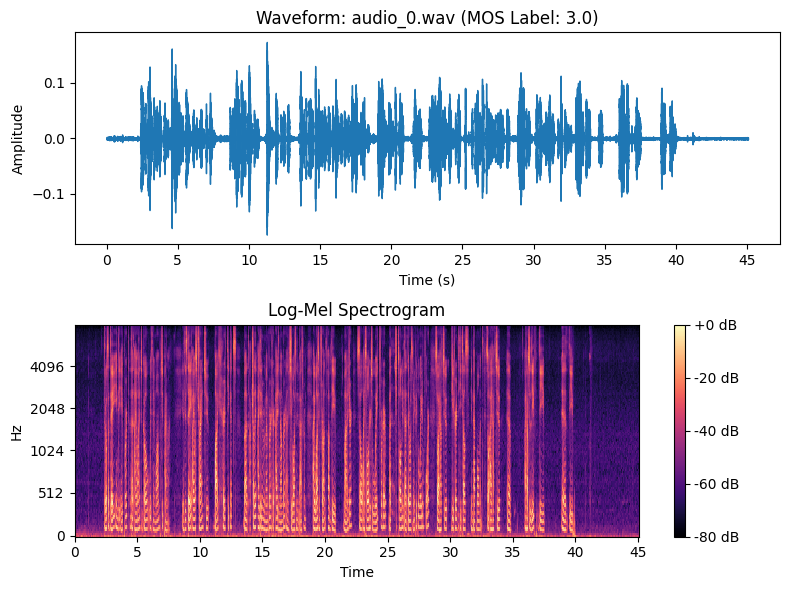

In [22]:

plt.figure(figsize=(8, 6))

# Subplot 1: Audio Waveform
plt.subplot(2, 1, 1)
librosa.display.waveshow(y, sr=sr)
plt.title(f"Waveform: {sample_filename} (MOS Label: {sample_label})")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")

# Subplot 2: Log-Mel Spectrogram
plt.subplot(2, 1, 2)
mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
librosa.display.specshow(mel_spec_db, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title("Log-Mel Spectrogram")

plt.tight_layout()
plt.show()

#### Now that we have loaded and inspected the train data, we can move ahead with the first approach.

In [24]:
#pip install openai-whisper

In [25]:
# importing torch, whisper, and tqdm to build the transcription pipeline


import torch
import whisper
from tqdm import tqdm

In [26]:
train_transcript_cache_path = os.path.join(folder_path, 'train_transcripts_cache.csv')

In [27]:
test_transcript_cache_path = os.path.join(folder_path, 'test_transcripts_cache.csv')

In [28]:
# the transcript cache file is created so that we do not have to run the transcription every time we re run the code,,

# once the transcript code runs, it will save the data in the file so that it can be retreived later without having the run the
# model again.




In [29]:
#pip install --upgrade transformers accelerate

In [30]:
from transformers import pipeline

In [31]:
if os.path.exists(train_transcript_cache_path):
    print(f"Loading cached transcripts from: {train_transcript_cache_path}")
    cache_df = pd.read_csv(train_transcript_cache_path)
    

    train_audio_data = pd.merge(train_audio_data, cache_df[['filename', 'transcript']], on='filename', how='left')
else:
    print("Loading Hugging Face Whisper ASR model...")
    

    if torch.backends.mps.is_available():
        device = "mps"
    else:
        device = "cpu"
        print("MPS not available. Running on CPU.")

    # Load Whisper pipeline with MPS device
    asr_pipe = pipeline(
        "automatic-speech-recognition", 
        model="openai/whisper-base", 
        device=device,
        chunk_length_s=30
    )

    transcripts = []
    print("Transcribing audio files...")

    for idx, row in tqdm(train_audio_data.iterrows(), total=len(train_audio_data)):
        fpath = row['file_path']
        try:
            y, sr = librosa.load(fpath, sr=16000)
            result = asr_pipe({"array": y, "sampling_rate": sr})
            text = result['text'].strip()
        except Exception as e:
            print(f"Error on {row['filename']}: {e}")
            text = ""
        transcripts.append(text)

    # Assign and cache results to CSV
    train_audio_data['transcript'] = transcripts
    train_audio_data[['audio_id', 'filename', 'transcript']].to_csv(train_transcript_cache_path, index=False)
    print(f"\nTranscripts successfully cached to {train_transcript_cache_path}")

# Previews
train_audio_data[['audio_id', 'filename', 'label', 'transcript']].head()

Loading cached transcripts from: /Users/aryansharma/Desktop/Dataset_Final/train_transcripts_cache.csv


,audio_id,filename,label,transcript
0,0,audio_0.wav,3.0,There was a day in the airport that I wanted t...
1,1,audio_1.wav,3.5,"Well, I usually travel a lot in the past, so I..."
2,2,audio_2.wav,2.5,"Okay, I am in our port. I am doing the line an..."
3,3,audio_3.wav,3.0,"Well, if we talk about a school program, it's ..."
4,4,audio_4.wav,2.5,So we come out for recess time and I go to pla...


In [32]:
# similarly transcribing test files ... ::


if os.path.exists(test_transcript_cache_path):
    print(f"Loading cached transcripts from: {test_transcript_cache_path}")
    cache_df = pd.read_csv(test_transcript_cache_path)
    

    test_audio_data = pd.merge(test_audio_data, cache_df[['filename', 'transcript']], on='filename', how='left')
else:
    print("Loading Hugging Face Whisper ASR model...")
    

    if torch.backends.mps.is_available():
        device = "mps"
    else:
        device = "cpu"
        print("MPS not available. Running on CPU.")

    # Load Whisper pipeline with MPS device
    asr_pipe = pipeline(
        "automatic-speech-recognition", 
        model="openai/whisper-base", 
        device=device,
        chunk_length_s=30
    )

    transcripts = []
    print("Transcribing audio files...")

    for idx, row in tqdm(test_audio_data.iterrows(), total=len(test_audio_data)):
        fpath = row['file_path']
        try:
            y, sr = librosa.load(fpath, sr=16000)
            result = asr_pipe({"array": y, "sampling_rate": sr})
            text = result['text'].strip()
        except Exception as e:
            print(f"Error on {row['filename']}: {e}")
            text = ""
        transcripts.append(text)

    # Assign and cache results to CSV
    test_audio_data['transcript'] = transcripts
    test_audio_data[['audio_id', 'filename', 'transcript']].to_csv(test_transcript_cache_path, index=False)
    print(f"\nTranscripts successfully cached to {test_transcript_cache_path}")

# Previews
test_audio_data[['audio_id', 'filename', 'label', 'transcript']].head()

Loading cached transcripts from: /Users/aryansharma/Desktop/Dataset_Final/test_transcripts_cache.csv


,audio_id,filename,label,transcript
0,0,audio_0.wav,-1,"So, of course, on a school playground, there w..."
1,1,audio_1.wav,-1,"And the last weekend, I went to my family to t..."
2,2,audio_2.wav,-1,"Well, we got to the resort. We went straight t..."
3,3,audio_3.wav,-1,There is two families in the airport that one ...
4,4,audio_4.wav,-1,The atmosphere in an April is one of the most ...


In [33]:
train_audio_data

,audio_id,filename,file_path,label,transcript
0,0,audio_0.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,3.0,There was a day in the airport that I wanted t...
1,1,audio_1.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,3.5,"Well, I usually travel a lot in the past, so I..."
2,2,audio_2.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,2.5,"Okay, I am in our port. I am doing the line an..."
3,3,audio_3.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,3.0,"Well, if we talk about a school program, it's ..."
4,4,audio_4.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,2.5,So we come out for recess time and I go to pla...
...,...,...,...,...,...
764,5069,audio_5069.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,0.0,"So, it's hard to do that. You can do it like t..."
765,5070,audio_5070.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,0.0,"I can't do it, I can't do it. I can't do it. I..."
766,5071,audio_5071.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,0.0,I'm going to take a nap. I'm going to take a n...
767,5072,audio_5072.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,0.0,"My goal is, I want to understand how much mone..."


In [34]:
test_audio_data


,audio_id,filename,file_path,label,transcript
0,0,audio_0.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,"So, of course, on a school playground, there w..."
1,1,audio_1.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,"And the last weekend, I went to my family to t..."
2,2,audio_2.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,"Well, we got to the resort. We went straight t..."
3,3,audio_3.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,There is two families in the airport that one ...
4,4,audio_4.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,The atmosphere in an April is one of the most ...
...,...,...,...,...,...
211,211,audio_211.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,my favorite holiday destination would be Malay...
212,212,audio_212.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,"Yeah, my TV show is one of the comedy show whi..."
213,213,audio_213.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,"Recently, Vardodara faced the flood. See, disa..."
214,214,audio_214.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,"To be honest, I love watching movies. I think ..."


In [35]:
# we have now successfully obtained the transcripted data for the train and test audio samples and can move ahead with the text feature extraction 

# and model development for MOS scoring. 



In [36]:
def extract_linguistic_features(df):
    features = []
    for text in df['transcript']:
        if not isinstance(text, str) or len(text.strip()) == 0:
            word_count = 0
            char_count = 0
            avg_word_len = 0
            unique_word_ratio = 0
        else:
            words = text.split()
            word_count = len(words)
            char_count = len(text)
            avg_word_len = sum(len(w) for w in words) / word_count if word_count > 0 else 0
            unique_word_ratio = len(set(words)) / word_count if word_count > 0 else 0
            
        features.append({
            'word_count': word_count,
            'char_count': char_count,
            'avg_word_len': avg_word_len,
            'unique_word_ratio': unique_word_ratio
        })
    return pd.DataFrame(features)

In [37]:
train_linguistic_features_df = extract_linguistic_features(train_audio_data)
train_model_df = pd.concat([train_audio_data, train_linguistic_features_df], axis=1)

In [38]:
train_model_df

,audio_id,filename,file_path,label,transcript,word_count,char_count,avg_word_len,unique_word_ratio
0,0,audio_0.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,3.0,There was a day in the airport that I wanted t...,88,393,3.477273,0.545455
1,1,audio_1.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,3.5,"Well, I usually travel a lot in the past, so I...",109,527,3.844037,0.642202
2,2,audio_2.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,2.5,"Okay, I am in our port. I am doing the line an...",85,410,3.835294,0.600000
3,3,audio_3.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,3.0,"Well, if we talk about a school program, it's ...",79,414,4.253165,0.696203
4,4,audio_4.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,2.5,So we come out for recess time and I go to pla...,101,472,3.683168,0.584158
...,...,...,...,...,...,...,...,...,...
764,5069,audio_5069.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,0.0,"So, it's hard to do that. You can do it like t...",799,4477,4.604506,0.041302
765,5070,audio_5070.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,0.0,"I can't do it, I can't do it. I can't do it. I...",497,1947,2.919517,0.028169
766,5071,audio_5071.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,0.0,I'm going to take a nap. I'm going to take a n...,274,1423,4.197080,0.058394
767,5072,audio_5072.wav,/Users/aryansharma/Desktop/Dataset_Final/train...,0.0,"My goal is, I want to understand how much mone...",1156,5686,3.919550,0.047578


In [39]:
# In this cell, we have extracted the linguistics for the test data as well however, for validation, only the train 
# data can be used as there are no lables with the original test data to validate.


test_linguistic_features_df = extract_linguistic_features(test_audio_data)
test_model_df = pd.concat([test_audio_data, test_linguistic_features_df], axis=1)

In [40]:
test_model_df

,audio_id,filename,file_path,label,transcript,word_count,char_count,avg_word_len,unique_word_ratio
0,0,audio_0.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,"So, of course, on a school playground, there w...",84,486,4.797619,0.690476
1,1,audio_1.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,"And the last weekend, I went to my family to t...",111,516,3.657658,0.504505
2,2,audio_2.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,"Well, we got to the resort. We went straight t...",120,569,3.750000,0.483333
3,3,audio_3.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,There is two families in the airport that one ...,97,481,3.969072,0.618557
4,4,audio_4.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,The atmosphere in an April is one of the most ...,99,547,4.535354,0.656566
...,...,...,...,...,...,...,...,...,...
211,211,audio_211.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,my favorite holiday destination would be Malay...,90,495,4.511111,0.677778
212,212,audio_212.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,"Yeah, my TV show is one of the comedy show whi...",90,448,3.988889,0.677778
213,213,audio_213.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,"Recently, Vardodara faced the flood. See, disa...",63,342,4.444444,0.714286
214,214,audio_214.wav,/Users/aryansharma/Desktop/Dataset_Final/test/...,-1,"To be honest, I love watching movies. I think ...",105,559,4.333333,0.733333


In [41]:
# Now we will be using TF-IDF vectorization to extract deeper text features from the transcription data instead of 

# only using the linguistic features, as it will be adding more depth to the model.


from sklearn.feature_extraction.text import TfidfVectorizer

print("Extracting TF-IDF features...")
tfidf = TfidfVectorizer(max_features=500, stop_words='english', ngram_range=(1, 2))
X_text = tfidf.fit_transform(train_audio_data['transcript'].fillna(''))

print(f"TF-IDF feature matrix shape: {X_text.shape}")

Extracting TF-IDF features...
TF-IDF feature matrix shape: (769, 500)


In [42]:
# Stacking the TF-IDF features along with the linguistic features:


from scipy.sparse import hstack, csr_matrix

# Convert numeric dataframe to numpy array
numeric_features = train_linguistic_features_df[['word_count', 'char_count', 'avg_word_len', 'unique_word_ratio']].values

# Stack numeric features and TF-IDF features horizontally
X_combined = hstack([csr_matrix(numeric_features), X_text])
y = train_audio_data['label'].values

print(f"Final stacked feature matrix shape: {X_combined.shape}")

Final stacked feature matrix shape: (769, 504)


##### Training classical regression models:

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

In [45]:
# need to split the training data to get the training, testing scores, as we do not have lables for the test data.

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(X_combined, y, train_size=0.75, random_state=30)

In [46]:

scores_dict = {}

for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    # Store metrics in the dictionary
    scores_dict[name] = {
        'RMSE': rmse,
        'MAE': mae,
        'R²': r2
    }

In [47]:
scores_dict

{'Ridge Regression': {'RMSE': 1.0357413626091438,
  'MAE': 0.8489666678480859,
  'R²': 0.273745595672486},
 'Random Forest': {'RMSE': 1.0112758703787819,
  'MAE': 0.7660362694300518,
  'R²': 0.30765042756402095},
 'Gradient Boosting': {'RMSE': 0.9944152969336407,
  'MAE': 0.7873557270166989,
  'R²': 0.33054447308102186}}

In [48]:
results_df = pd.DataFrame.from_dict(scores_dict, orient='index')

In [49]:
display(results_df)

,RMSE,MAE,R²
Ridge Regression,1.035741,0.848967,0.273746
Random Forest,1.011276,0.766036,0.307650
Gradient Boosting,0.994415,0.787356,0.330544


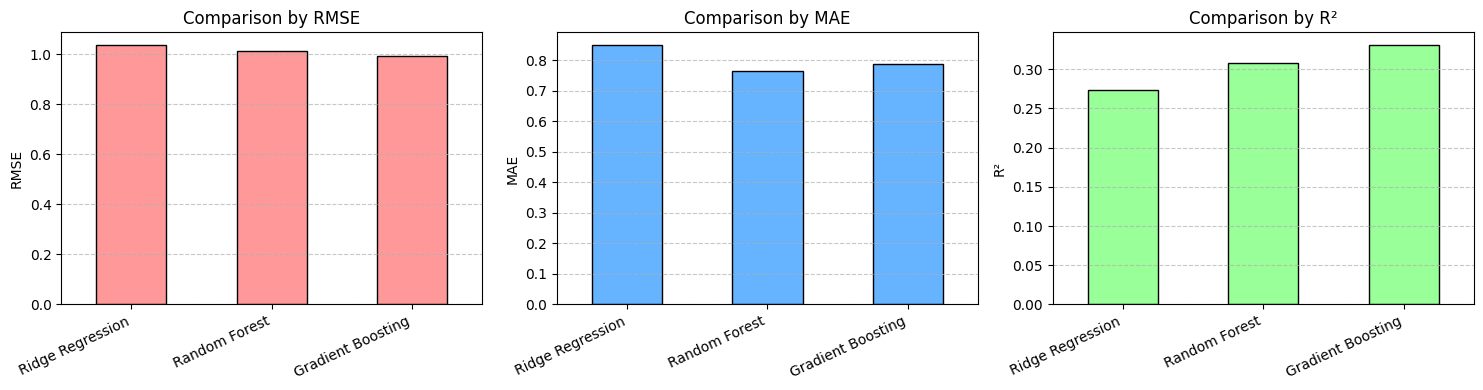

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
metrics = ['RMSE', 'MAE', 'R²']
colors = ['#ff9999', '#66b3ff', '#99ff99']

for i, metric in enumerate(metrics):
    results_df[metric].plot(kind='bar', ax=axes[i], color=colors[i], edgecolor='black')
    axes[i].set_title(f'Comparison by {metric}')
    axes[i].set_ylabel(metric)
    axes[i].set_xticklabels(results_df.index, rotation=25, ha='right')
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

##### Training an Artificial Neural network

In [52]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

In [53]:
X_train_dense = x_train.toarray()
X_test_dense = x_test.toarray()

In [54]:
keras_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_dense.shape[1],)),
    Dense(128, activation='relu', input_shape=(X_train_dense.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='linear') # Linear activation for continuous regression output (0-5 MOS)
])

In [55]:
keras_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mean_squared_error',
    metrics=['mae']
)

In [56]:
print("Training Keras Sequential ANN...")
history = keras_model.fit(
    X_train_dense, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=32,
    verbose=1 
)
print("Training complete!")

# 5. Evaluate on Test Set
y_pred_keras = keras_model.predict(X_test_dense).flatten()

keras_rmse = np.sqrt(mean_squared_error(y_test, y_pred_keras))
keras_mae = mean_absolute_error(y_test, y_pred_keras)
keras_r2 = r2_score(y_test, y_pred_keras)

print(f"\n--- Keras Sequential ANN Evaluation ---")
print(f"RMSE: {keras_rmse:.4f} | MAE: {keras_mae:.4f} | R²: {keras_r2:.4f}")

# 6. Add to our scores dictionary and update comparison
scores_dict["Keras Sequential ANN"] = {
    'RMSE': keras_rmse,
    'MAE': keras_mae,
    'R²': keras_r2
}


Training Keras Sequential ANN...
Epoch 1/100
17/17 [==============================] - 0s 5ms/step - loss: 764.0515 - mae: 16.7422 - val_loss: 136.0398 - val_mae: 10.7224
Epoch 2/100
17/17 [==============================] - 0s 1ms/step - loss: 393.0807 - mae: 10.9029 - val_loss: 15.0071 - val_mae: 3.6895
Epoch 3/100
17/17 [==============================] - 0s 2ms/step - loss: 188.7659 - mae: 8.4450 - val_loss: 15.4252 - val_mae: 3.7112
Epoch 4/100
17/17 [==============================] - 0s 1ms/step - loss: 140.0971 - mae: 6.9384 - val_loss: 9.4141 - val_mae: 2.8746
Epoch 5/100
17/17 [==============================] - 0s 1ms/step - loss: 110.6069 - mae: 6.4521 - val_loss: 11.5197 - val_mae: 3.2057
Epoch 6/100
17/17 [==============================] - 0s 1ms/step - loss: 78.0645 - mae: 4.9619 - val_loss: 8.4154 - val_mae: 2.7054
Epoch 7/100
17/17 [==============================] - 0s 1ms/step - loss: 71.3128 - mae: 5.0714 - val_loss: 4.6650 - val_mae: 1.9603
Epoch 8/100
17/17 [===========

In [57]:

results_df = pd.DataFrame(scores_dict).T
print("\n--- Final Updated Results Table ---")
display(results_df)


--- Final Updated Results Table ---


,RMSE,MAE,R²
Ridge Regression,1.035741,0.848967,0.273746
Random Forest,1.011276,0.766036,0.307650
Gradient Boosting,0.994415,0.787356,0.330544
Keras Sequential ANN,1.121406,0.922800,0.148643


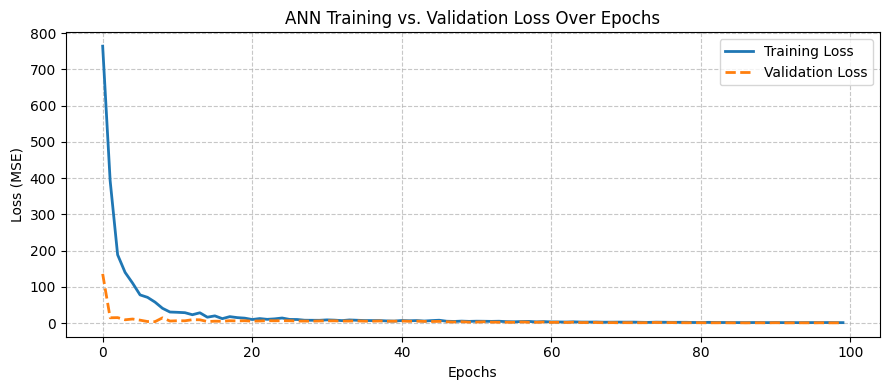

In [58]:
plt.figure(figsize=(9, 4))
plt.plot(history.history['loss'], label='Training Loss', color='#1f77b4', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss', color='#ff7f0e', linewidth=2, linestyle='--')
plt.title('ANN Training vs. Validation Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#### Moving to the second defined approach, that combines sentence transformer, with linguistic and prasody features

In [60]:
#pip install sentence-transformers

In [61]:
# The current RMSE shows that the classical ML model, paired only with the linguistic and vectorised features extracted from the text,

# have low predictive power. 

# For an improved approach, we are trying out with pair of sentense embeddings to represent the semantic meaning better, with acoustic prasody 

# features to deepen the speech variability of the models.


from sentence_transformers import SentenceTransformer

# Utilising pretrained setense transformer to generate embeddings.

embed_model = SentenceTransformer('all-MiniLM-L6-v2')


Loading weights: 100%|█████████████████████| 103/103 [00:00<00:00, 8668.53it/s]


In [62]:
# Creating a function to extract the embeddings, linguistic features, and prasody features for the dataset.

# function creation here will minimise repetition of code, as we will require the same pipeline with the final unlabelled test data as well.




def extract_hybrid_features(df, embed_model):
    """
    Extracts semantic sentence embeddings and acoustic prosody/MFCC features 
    from a given dataframe containing transcripts and file paths.
    """
    print(f"Processing {len(df)} samples...")
    
    # 1. Generate Semantic Embeddings (384-dim)
    texts = df['transcript'].fillna("").tolist()
    embeddings = embed_model.encode(texts, show_progress_bar=True)
    
    # 2. Extract Acoustic Prosody and MFCC Features (19-dim)
    audio_features_list = []
    
    for idx, row in df.iterrows():
        fpath = row['file_path']
        transcript = row['transcript']
        
        try:
            y, sr = librosa.load(fpath, sr=16000)
            duration = librosa.get_duration(y=y, sr=sr)
            
            # Linguistic & Prosody stats
            word_count = len(str(transcript).split())
            speaking_rate = word_count / duration if duration > 0 else 0
            rms = librosa.feature.rms(y=y)
            rms_mean = np.mean(rms)
            rms_std = np.std(rms)
            spectral_centroid = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
            
            # MFCC extraction
            mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
            mfcc_means = np.mean(mfccs, axis=1) # 13 values
            
            # Combine individual audio stats
            row_features = [duration, word_count, speaking_rate, rms_mean, rms_std, spectral_centroid] + list(mfcc_means)
            audio_features_list.append(row_features)
            
        except Exception as e:
            # Fallback vector of zeros if an audio file fails to load
            audio_features_list.append([0] * 19)
            
    audio_features_array = np.array(audio_features_list)
    
    # 3. Combine Semantic Embeddings + Audio/MFCC Features
    X_hybrid = np.hstack([embeddings, audio_features_array])
    
    return X_hybrid

In [63]:
X_hybrid = extract_hybrid_features(train_audio_data, embed_model=embed_model)
y = train_audio_data['label'].values

Processing 769 samples...


Batches: 100%|█████████████████████████████████| 25/25 [00:03<00:00,  6.28it/s]


In [64]:
X_hybrid.shape

(769, 403)

In [65]:
y.shape

(769,)

In [66]:
# split

x_train_hybrid, x_test_hybrid, y_train_hybrid, y_test_hybrid = train_test_split(X_hybrid,y, train_size=0.75, random_state=30)

In [67]:
from scipy.stats import pearsonr

In [68]:
print("Training Gradient Boosting Regressor on hybrid features...")
gb_model = GradientBoostingRegressor(
    n_estimators=110, 
    learning_rate=0.01, 
    max_depth=3, 
    random_state=42
)
gb_model.fit(x_train_hybrid, y_train_hybrid)

# 6. Evaluation with Mandatory Training & Test RMSE
y_train_pred = gb_model.predict(x_train_hybrid)
y_test_pred = gb_model.predict(x_test_hybrid)

train_rmse = np.sqrt(mean_squared_error(y_train_hybrid, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test_hybrid, y_test_pred))
pearson_corr, _ = pearsonr(y_test_hybrid, y_test_pred)
r2 = r2_score(y_test_hybrid, y_test_pred)



print("========================================")
print(f"Training RMSE : {train_rmse:.4f} ")
print(f"Pearson Corr  : {pearson_corr:.4f}")
print(f"Test R² Score : {r2:.4f}")
print("========================================")

Training Gradient Boosting Regressor on hybrid features...
Training RMSE : 0.8723 
Pearson Corr  : 0.6083
Test R² Score : 0.3230


In [69]:
# Utilising the original test set to predict continuous MOS score for the test samples:

# To do this, we need to process the test transcript and its data according to input requirement of final model, requiring sentence transformer and 

# combination of semantic embeddings with MFCC features.


In [70]:
# now we can use the 'extract_hybrid_features' function to process the train data as well.


x_test_hybrid = extract_hybrid_features(test_audio_data, embed_model=embed_model)



Processing 216 samples...


Batches: 100%|███████████████████████████████████| 7/7 [00:01<00:00,  6.36it/s]


In [71]:
# Predictions : passing the data into the model


gb_model.predict(x_test_hybrid)

array([3.43023988, 3.26227351, 3.51372756, 3.25728611, 3.28194776,
       3.31849886, 3.44935576, 3.84054729, 3.15185458, 3.31030017,
       3.28818994, 3.23612101, 3.42423267, 3.5036605 , 3.36528222,
       3.27821118, 3.43651399, 3.02691817, 3.48094948, 3.34939136,
       3.28385048, 3.01917695, 3.14241949, 3.15996317, 3.16481212,
       3.5095453 , 3.17692486, 3.32049832, 3.28819145, 3.32841489,
       3.53305413, 3.44110905, 3.32247871, 3.33713037, 3.56351332,
       3.48212261, 3.49148393, 3.88399877, 3.17985777, 3.22848078,
       3.50697912, 3.52027509, 3.51226713, 3.96290174, 3.32235345,
       3.81074298, 3.75677486, 3.60125286, 3.37228773, 3.37953886,
       3.31743792, 3.70891771, 3.82507103, 3.35910574, 3.34269208,
       3.47251111, 3.76684414, 3.39652458, 3.19471185, 3.63631864,
       3.38528912, 3.26741557, 3.71902729, 3.45640138, 3.0555695 ,
       3.14097613, 3.32145822, 3.58563191, 3.80068665, 3.58854986,
       3.59249598, 3.55796278, 3.75777657, 3.4827172 , 3.84020

### This is the end of the code part, adding final verdict and conclusions below

### Conclusive note and self identified areas of improvement

#### Thank You ! 